# Sep-15

* temperature 5MeV, 15MeV, 40MeV
* $n_crit = 2.5n_0,\; 3n_0,\; 4n_0$
* use equaly spaced contour in the 2 by 2, use same levels numbers

## Testing the new version of the code

In [7]:
import RMFsolver.RMFparameter as para
import RMFsolver.constants as const
import RMFsolver.phase_velocity as phv
import RMFsolver.phase_velocity_old as phv_o

n0 = 0.16 * const.MeV_fm**3

v1 = phv_o.Get_Delta_P_max(
    T = 15,
    P_crit = 3e8,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    method = "numerical"
)

v2 = phv.Get_Delta_P_max(
    T = 15,
    P_crit = 3e8,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
)

v1, v2, v1/v2

(566563145.9994953, 566563145.9994953, 1.0)

In [12]:
t1, z1 = phv_o.z_time_evolution(pressure, radius, P_c=P_crit, T=15)
t2, z2 = phv.z_time_evolution(pressure, radius, P_c=P_crit, T=15)

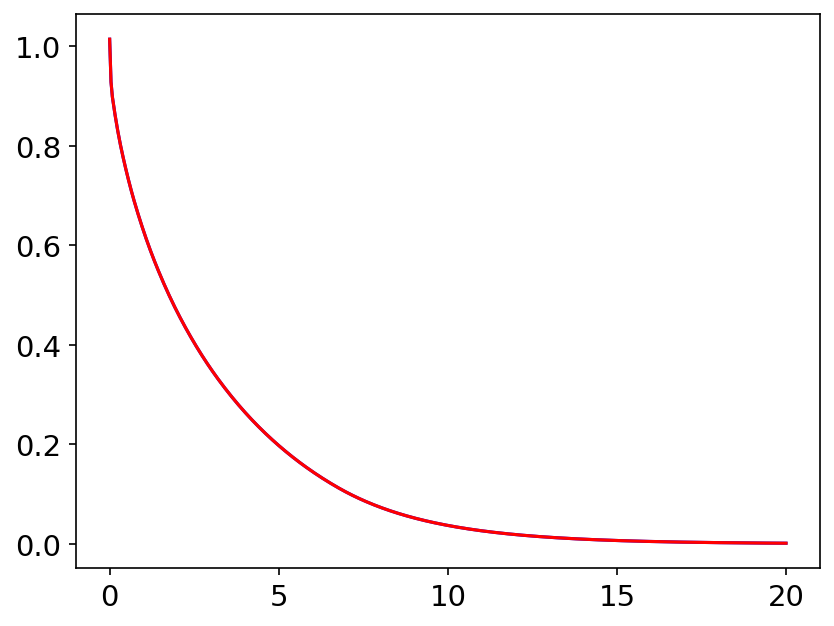

In [15]:
plt.plot(t1, z1, 'b')
plt.plot(t2, z2, 'r')

## Get $z(t)$ curve with different input

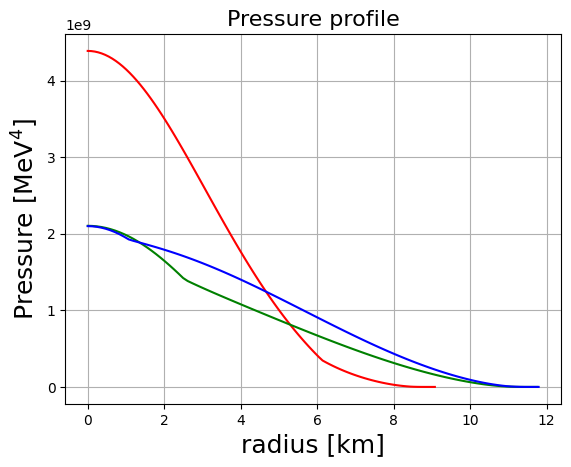

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import interp1d
from fractions import Fraction

# Read CSV (skip the header row if it exists)
df1 = pd.read_csv("pressure_of_radius_pMeV4_2.5n0.csv")
df2 = pd.read_csv("pressure_of_radius_pMeV4_4n0.csv")
df3 = pd.read_csv("pressure_of_radius_pMeV4_4.5n0.csv")

# Convert the first column (fractions as strings) to floats
radius1 = df1.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure1 = df1.iloc[:, 1]

radius2 = df2.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure2 = df2.iloc[:, 1]

radius3 = df3.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure3 = df3.iloc[:, 1]

# Convert to numpy arrays if needed
radius1 = radius1.to_numpy(dtype=float)
radius2 = radius2.to_numpy(dtype=float)
radius3 = radius3.to_numpy(dtype=float)
pressure1 = pressure1.to_numpy(dtype=float)
pressure2 = pressure2.to_numpy(dtype=float)
pressure3 = pressure3.to_numpy(dtype=float)

P_of_r1 = interp1d(radius1, pressure1, kind="linear", fill_value="extrapolate")
P_of_r2 = interp1d(radius2, pressure2, kind="linear", fill_value="extrapolate")
P_of_r3 = interp1d(radius3, pressure3, kind="linear", fill_value="extrapolate")

r_test1 = np.linspace(radius1.min(), radius1.max(), 100)
r_test2 = np.linspace(radius2.min(), radius2.max(), 100)
r_test3 = np.linspace(radius3.min(), radius3.max(), 100)
P_test1 = np.array([P_of_r1(ele) for ele in r_test1])
P_test2 = np.array([P_of_r2(ele) for ele in r_test2])
P_test3 = np.array([P_of_r3(ele) for ele in r_test3])

plt.plot(r_test1, P_test1, 'r')
plt.plot(r_test2, P_test2, 'g')
plt.plot(r_test3, P_test3, 'b')

#plt.scatter(6.1, P_of_r(6.1), marker="*", c='r', s=100)
#plt.text(6.2, P_of_r(6.1)*1.1, rf"Critical", fontsize=16)
#plt.plot(radius, pressure, 'b')

plt.title("Pressure profile", fontsize = 16)
plt.xlabel(rf"radius [km]", fontsize = 18)
plt.ylabel(rf"Pressure [MeV$^4$]", fontsize = 18)
plt.grid()
plt.show()

In [2]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, Get_Delta_P_max, _find_muB_muK_star

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

T = 15
n_crit1 = 2.5 * n0
n_crit2 = 4.0 * n0
n_crit3 = 4.5 * n0
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"


# solve for bag constant
P_crit1 = PNM_n(n_crit1, T)
P_crit2 = PNM_n(n_crit2, T)
P_crit3 = PNM_n(n_crit3, T)

In [3]:
P_crit1/1e8, P_crit2/1e8, P_crit3/1e8

(3.542592408984268, 14.067694324311457, 19.294823476770343)

In [7]:
from RMFsolver.phase_velocity import z_time_evolution

Temp_list = [5, 15, 45]

t1 = []
z1 = []
t2 = []
z2 = []
t3 = []
z3 = []

for Te in Temp_list:
    tt1, zz1, z01, r_crit1 = z_time_evolution(
        Pressure_arr = pressure1, 
        radius_arr = radius1,
        P_c = P_crit1,
        T = Te, 
        Interp1d_Num = 10,
    )
    
    tt2, zz2, z02, r_crit2 = z_time_evolution(
        Pressure_arr = pressure2, 
        radius_arr = radius2,
        P_c = P_crit2,
        T = Te, 
        Interp1d_Num = 10,
    )
    
    tt3, zz3, z03, r_crit3 = z_time_evolution(
        Pressure_arr = pressure3, 
        radius_arr = radius3,
        P_c = P_crit3,
        T = Te, 
        Interp1d_Num = 10,
    )

    t1.append(tt1)
    z1.append(zz1)
    
    t2.append(tt2)
    z2.append(zz2)

    t3.append(tt3)
    z3.append(zz3)
    print(Te)

5
15
45


In [43]:
Te = 0.1

tt1, zz1, z01, r_crit1 = z_time_evolution(
    Pressure_arr = pressure1, 
    radius_arr = radius1,
    P_c = P_crit1,
    T = Te, 
    Interp1d_Num = 10,
)

tt2, zz2, z02, r_crit2 = z_time_evolution(
    Pressure_arr = pressure2, 
    radius_arr = radius2,
    P_c = P_crit2,
    T = Te, 
    Interp1d_Num = 10,
)

tt3, zz3, z03, r_crit3 = z_time_evolution(
    Pressure_arr = pressure3, 
    radius_arr = radius3,
    P_c = P_crit3,
    T = Te, 
    Interp1d_Num = 10,
)

t1.append(tt1)
z1.append(zz1)

t2.append(tt2)
z2.append(zz2)

t3.append(tt3)
z3.append(zz3)

/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:949: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(fun, x0, xtol=1e-6, maxfev=400)[0]
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:949: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(fun, x0, xtol=1e-6, maxfev=400)[0]
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:949: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(fun, x0, xtol=1e-6, maxfev=400)[0]
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:949: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(fun, x0, xtol=1e-6, maxfev=400)[0]
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:949: RuntimeW

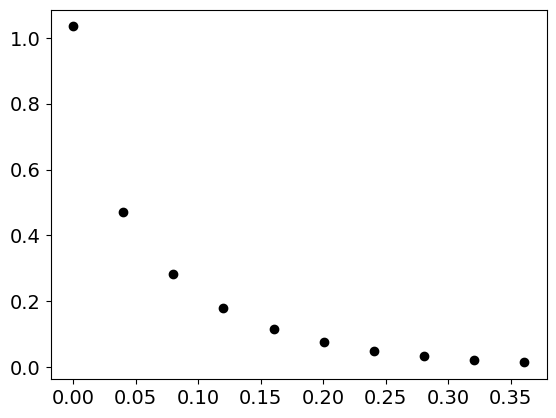

In [57]:
#plt.plot(t1[0], z1[0], 'b')
#plt.plot(t1[1], z1[1], 'g')
#plt.plot(t1[2], z1[2], 'r')
plt.scatter(t1[3][:10], z1[3][:10], c='k')
#plt.yscale("log")

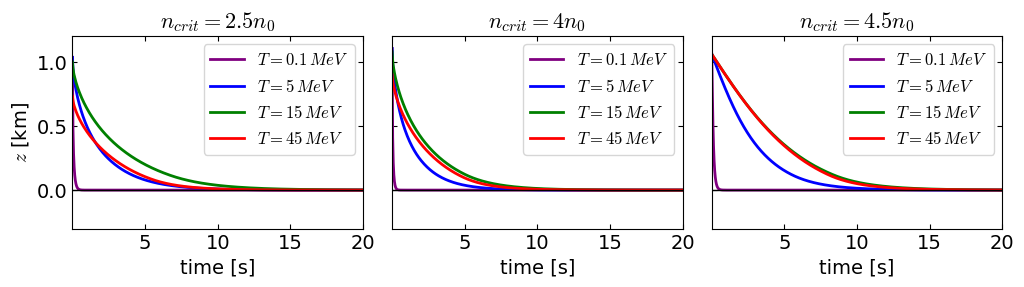

In [51]:
import matplotlib as mpl
fig, axs = plt.subplots(1, 3, figsize=(12, 2.5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)

mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

axs[0].plot(t1[3], z1[3], lw=2, c='purple', label = rf"$T=0.1\,MeV$")
axs[0].plot(t1[0], z1[0], lw=2, c='b', label = rf"$T=5\,MeV$")
axs[0].plot(t1[1], z1[1], lw=2, c='g', label = rf"$T=15\,MeV$")
axs[0].plot(t1[2], z1[2], lw=2, c='r', label = rf"$T=45\,MeV$")
axs[0].plot(np.linspace(0,20,100), np.zeros(100), 'k', lw=1)
axs[0].set_xlim(5e-4, 20)
axs[0].set_ylim(-0.3, 1.2)
axs[0].set_title(rf"$n_{{crit}} = 2.5n_0$", fontsize=16)
axs[0].set_xlabel(rf"time [s]", fontsize=14)
axs[0].set_ylabel(rf"$z$ [km]", fontsize=14)
#axs[0].set_yscale("log")
axs[0].legend(fontsize=12)
axs[0].tick_params(which='both', direction='in', top=True, right=True)

axs[1].plot(t2[3], z2[3], lw=2, c='purple', label = rf"$T=0.1\,MeV$")
axs[1].plot(t2[0], z2[0], lw=2, c='b', label = rf"$T=5\,MeV$")
axs[1].plot(t2[1], z2[1], lw=2, c='g', label = rf"$T=15\,MeV$")
axs[1].plot(t2[2], z2[2], lw=2, c='r', label = rf"$T=45\,MeV$")
axs[1].plot(np.linspace(0,20,100), np.zeros(100), 'k', lw=1)
axs[1].set_xlim(5e-4, 20)
axs[1].set_ylim(-0.3, 1.2)
axs[1].set_title(rf"$n_{{crit}} = 4n_0$", fontsize=16)
axs[1].set_xlabel(rf"time [s]", fontsize=14)
#axs[1].set_ylabel(rf"$z$ [km]", fontsize=14)
#axs[1].set_yscale("log")
axs[1].legend(fontsize=12)
axs[1].tick_params(which='both', direction='in', top=True, right=True)

axs[2].plot(t3[3], z3[3], lw=2, c='purple', label = rf"$T=0.1\,MeV$")
axs[2].plot(t3[0], z3[0], lw=2, c='b', label = rf"$T=5\,MeV$")
axs[2].plot(t3[1], z3[1], lw=2, c='g', label = rf"$T=15\,MeV$")
axs[2].plot(t3[2], z3[2], lw=2, c='r', label = rf"$T=45\,MeV$")
axs[2].plot(np.linspace(0,20,100), np.zeros(100), 'k', lw=1)
axs[2].set_xlim(5e-4, 20)
axs[2].set_ylim(-0.3, 1.2)
axs[2].set_title(rf"$n_{{crit}} = 4.5n_0$", fontsize=16)
axs[2].set_xlabel(rf"time [s]", fontsize=14)
#axs[2].set_ylabel(rf"$z$ [km]", fontsize=14)
#axs[2].set_yscale("log")
axs[2].legend(fontsize=12)
axs[2].tick_params(which='both', direction='in', top=True, right=True)

#plt.savefig("Various_z(t)_new.pdf", bbox_inches="tight")

In [3]:
from RMFsolver.phase_velocity import Get_Delta_P_max
Get_Delta_P_max(15, P_crit2, 0, para.paraQMCRMF3, "PNM", tol=5e-3)

449265394.6192137

In [5]:
from RMFsolver.phase_velocity import Get_Delta_P_max
Get_Delta_P_max(45, P_crit2, 0, para.paraQMCRMF3, "PNM", tol=5e-3)

387613976.3987282

In [32]:
(P_crit3 + 387613976.3987282) / pressure3[0]

np.float64(1.1037846643614622)

In [6]:
from RMFsolver.phase_velocity import Get_Two_as_pres
Get_Two_as_pres(45, P_crit2, 387613976.3987282, 0, para.paraQMCRMF3, "PNM")

(np.float64(0.4782382772925067), np.float64(0.48229557867583767))

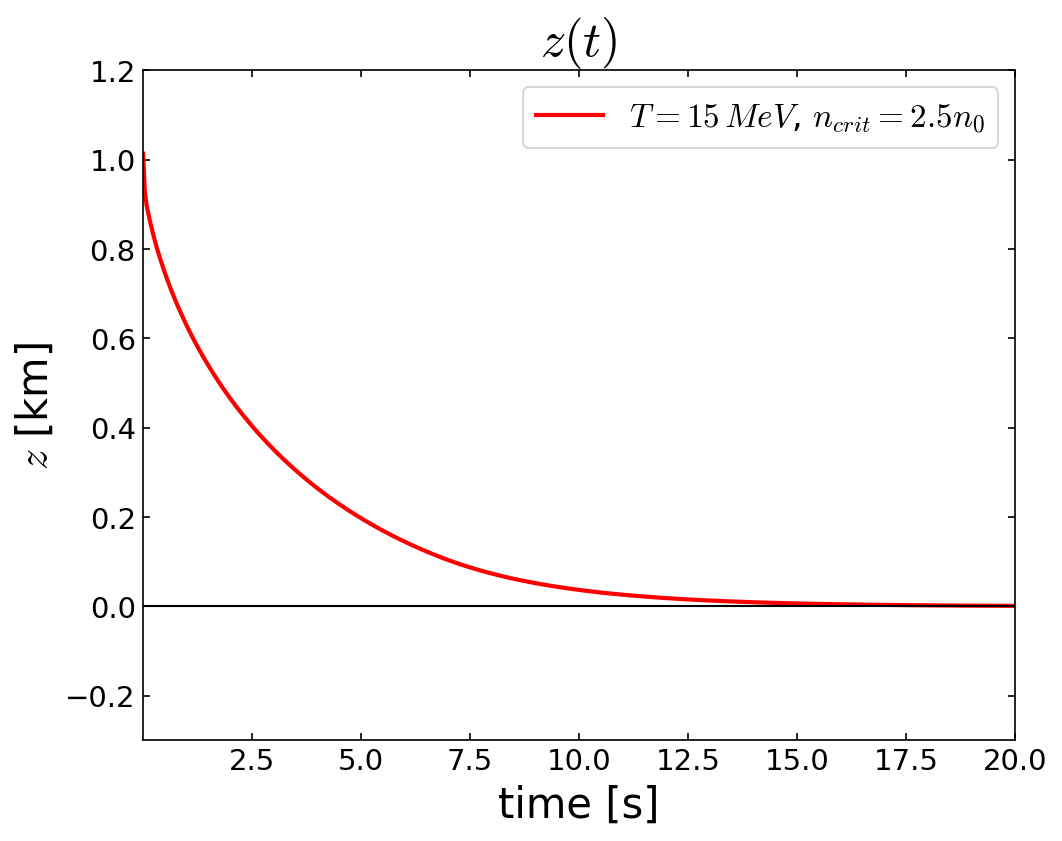

In [97]:
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

plt.plot(tt, zz, lw=2, c='r', label = rf"$T=15\,MeV$, $n_{{crit}} = 2.5n_0$")
plt.plot(np.linspace(0,20,100), np.zeros(100), 'k', lw=1)
plt.xlim(5e-4, 20)
plt.ylim(-0.3, 1.2)
plt.title(rf"$z(t)$", fontsize=24)
plt.xlabel(rf"time [s]", fontsize=20)
plt.ylabel(rf"$z$ [km]", fontsize=20)
#plt.xscale("log")
#plt.yscale("log")
#plt.xticks(np.array([1e-3, 1e-2, 1e-1, 1, 10, 20])*1e3)
plt.legend(fontsize=16)
plt.tick_params(which='both', direction='in', top=True, right=True)

plt.savefig("z(t)_T15_nc2.5.pdf")

In [103]:
z0 = 1.0136903211671218
z_list = np.hstack([np.linspace(0, 0.08, 35), np.linspace(0.081, 0.8*z0, 15), np.linspace(0.8*z0, z0, 50)])
z_crit = 6.117599868035375
v_list = []
def vz_accurate(z):
    DelP_P_crit = P_of_r(z_crit - z)
    vel, _ = vNtoQ_Pc(T=15.0, P_crit = P_crit, DelP = DelP_P_crit - P_crit, m_s = 0, param = para.paraQMCRMF3, NM_type = "PNM")
    return vel / 1e3 # in km/s

for i in range(len(z_list)):
    v_list.append(vz_accurate(z_list[i]))
    print(i)
    
v_list = np.array(v_list) # np.array([vz_accurate(z) for z in z_list])

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


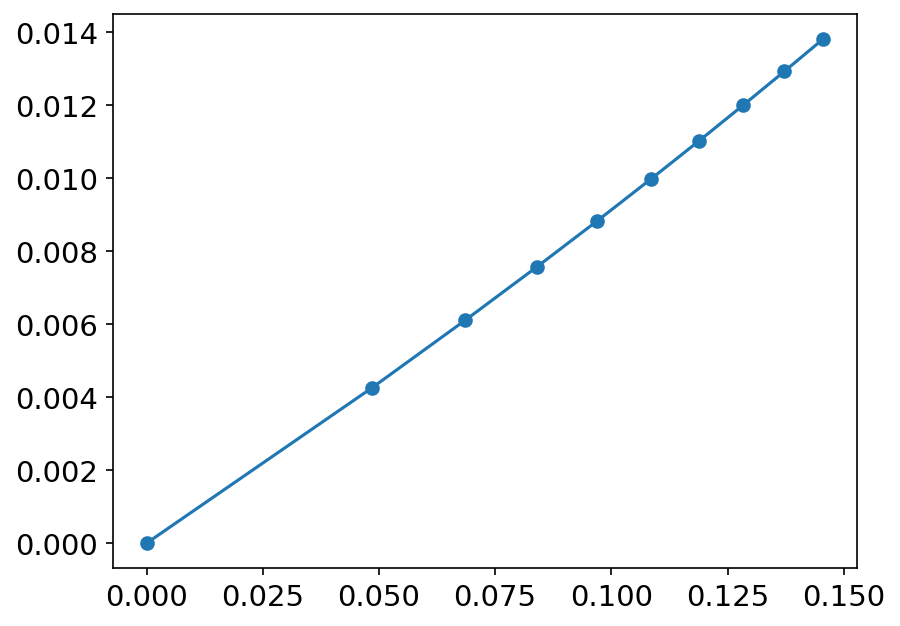

In [109]:
plt.plot(np.sqrt(z_list[:10]), v_list[:10], marker='o')

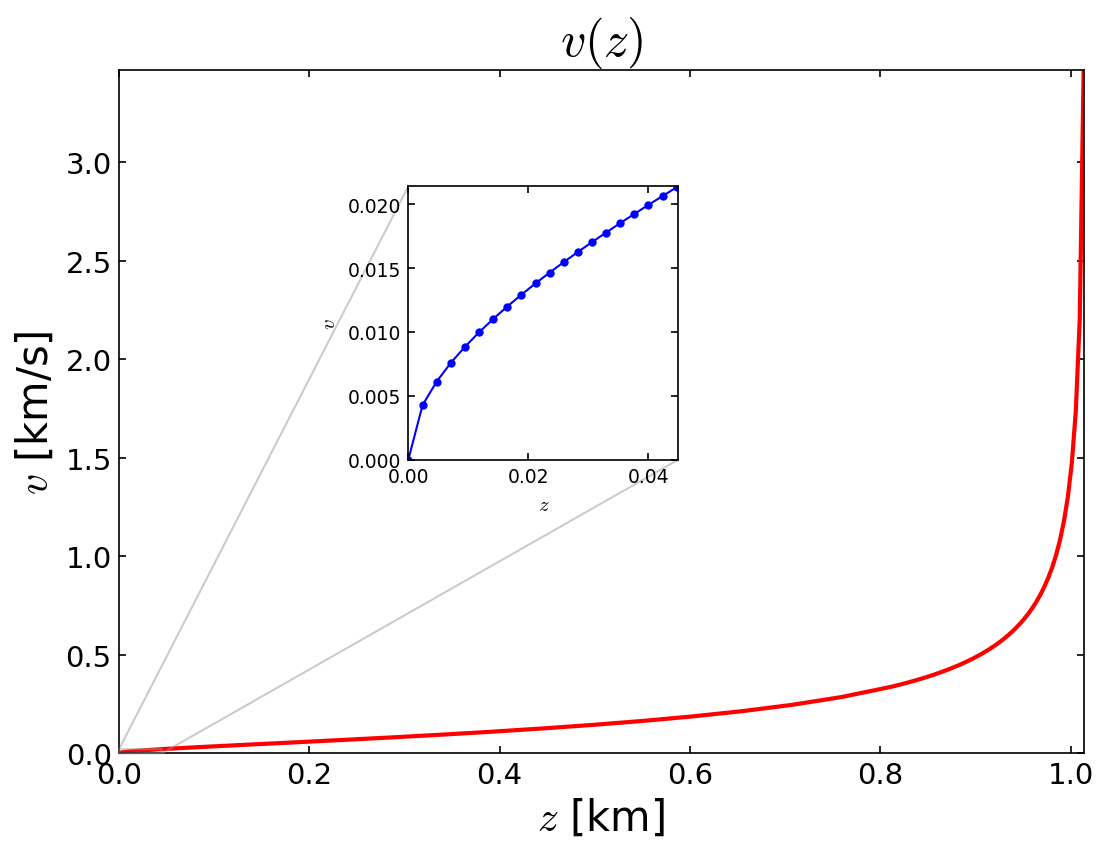

In [107]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.axes import Axes

vz_interp1d = interp1d(z_list, v_list, kind="linear", fill_value="extrapolate")

# --- main figure/axes ---
fig, ax = plt.subplots(figsize=(7.5, 5.8), dpi=150)

# main curve (keep your split if you need to skip a bad point around index 25)
ax.plot(z_list, np.array([vz_interp1d(z) for z in z_list]), 'r', lw=2)
#ax.plot(z_list[26:], v_list[26:], 'b', lw=2)

ax.set_xlabel(r"$z$ [km]", fontsize=20)
ax.set_ylabel(r"$v$ [km/s]", fontsize=20)
ax.set_title(r"$v(z)$", fontsize=24)
ax.set_xlim(0, z0)
ax.set_ylim(0, float(vz_interp1d(z0)))
#ax.set_yscale("log")

# -----------------------------
# inset (zoom near z=0)
# -----------------------------
# place inset by fractions of the main-axes (x0, y0, width, height)
# this puts it more centered (upper-middle). Tweak if you like.
axins: Axes = ax.inset_axes([0.30, 0.43, 0.28, 0.4])  # [left, bottom, width, height] in axes coords

# Option A: plot the SAME slices to avoid crossing lines
axins.plot(z_list[:20], np.array([vz_interp1d(z) for z in z_list])[:20], 'b', lw=1, marker='.')
#axins.plot(z_list[26:], v_list[26:], 'b', lw=2)

# Option B (alternative): sort before plotting (comment A and uncomment B if preferred)
# idx = np.argsort(z_list)
# axins.plot(np.asarray(z_list)[idx], np.asarray(v_list)[idx], 'b', lw=2)

# zoom limits (adjust to your data scale)
z_max_zoom = 0.045 #np.sqrt(z_list[20])
axins.set_xlim(0, z_max_zoom)
axins.set_ylim(0, float(vz_interp1d(z_max_zoom)))
axins.set_xlabel(rf"$z$")
axins.set_ylabel(rf"$v$")
axins.tick_params(which='both', direction='in', top=True, right=True)

# smaller ticks for inset
axins.tick_params(labelsize=9)

# draw a neat rectangle on the main axes to indicate the zoomed region
# (Matplotlib 3.1+)
ax.indicate_inset_zoom(axins, edgecolor="0.6")
ax.tick_params(which='both', direction='in', top=True, right=True)

fig.tight_layout()
fig.savefig("v(z).pdf")
plt.show()

## rep-spacing the 2 by 2 contours

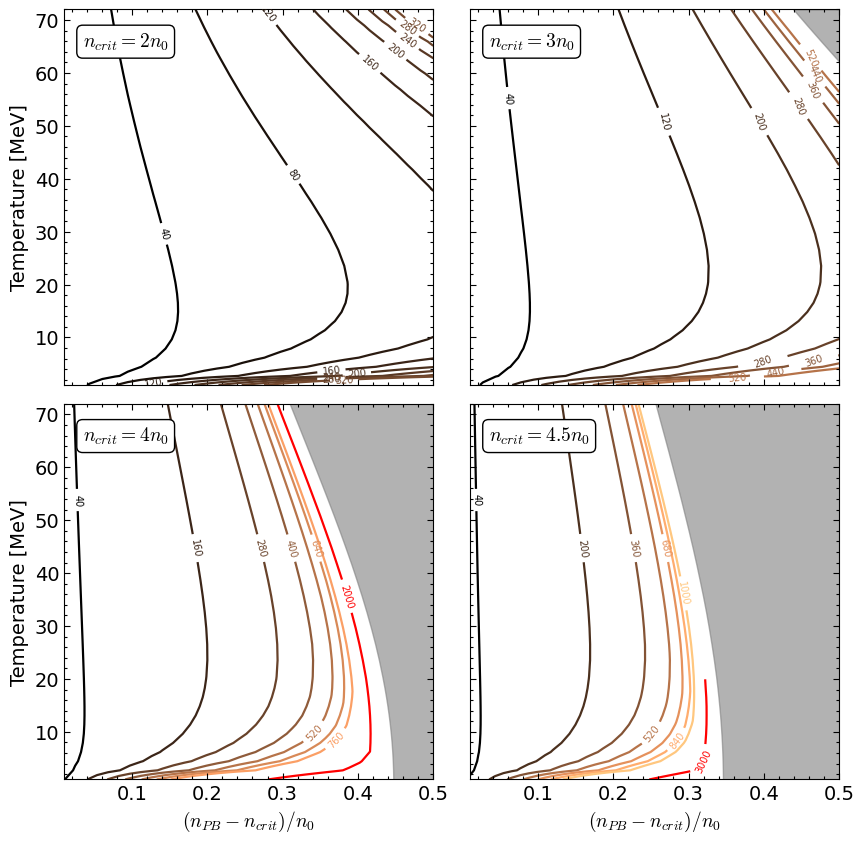

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM
import matplotlib.colors as mcolors

# Define n0 (adjust as needed)
n0 = 0.16 * const.MeV_fm**3

nc2, nc3, nc4, nc5 = 2*n0, 3*n0, 4*n0, 4.5*n0
N = 30
path = "/Users/janshao/NSM_related/v_0.002n0/"
path_safe = "/Users/janshao/NSM_related/v_0.015n0_safe/"

al = 0.6

# shaded region
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3.0.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind='linear', fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load("Shade_n_crit=4.0.npy")
Cut4 = interp1d(T_cut4, Deln_cut4, kind='linear', fill_value="extrapolate")

Deln_cut4_5, T_cut4_5 = np.load("Shade_n_crit=4.5.npy")
Cut4_5 = interp1d(T_cut4_5, Deln_cut4_5, kind='linear', fill_value="extrapolate")

# ------------------------------------------------------------------------------------
# Levels per subplot
# ------------------------------------------------------------------------------------
levels_11 = np.concatenate([[40+40*i for i in range(8)]])               # 8 levels
levels_12 = np.concatenate([[40+80*i for i in range(7)]])               # 7 levels
levels_21 = np.concatenate([[40+120*i for i in range(7)], [2000]])      # plus special 2000
levels_22 = np.concatenate([[40+160*i for i in range(7)], [3000]])      # plus special 3000

# Global set of all levels
ALL_LEVELS = np.unique(np.concatenate([levels_11, levels_12, levels_21, levels_22]))

# ------------------- COLOR MAPPING (updated) -------------------
# Regular levels colored by a high-contrast colormap; special 2000 & 3000 in red
SPECIAL_LEVELS = {2000, 3000}
NORMAL_LEVELS = np.array(sorted([l for l in ALL_LEVELS if l not in SPECIAL_LEVELS]))

# 'inferno' is high-contrast and readable; PowerNorm boosts mid/high contrast a bit
cmap = plt.get_cmap('copper') # inferno, copper
norm = mcolors.PowerNorm(gamma=0.8, vmin=NORMAL_LEVELS.min(), vmax=NORMAL_LEVELS.max())

LEVEL_COLOR = {
    lev: (1.0, 0.0, 0.0, 1.0) if lev in SPECIAL_LEVELS else cmap(norm(lev))
    for lev in ALL_LEVELS
}
# ---------------------------------------------------------------

def contour_with_fixed_colors(ax, X, Y, Z, levels, **kwargs):
    cols = [LEVEL_COLOR[lev] for lev in levels]
    cs = ax.contour(X, Y, Z, levels=levels, colors=cols, **kwargs)
    ax.clabel(cs, inline=True, fontsize=7, fmt="%d")
    return cs

# create plots
fig, axs = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)

# Common T grid
TT = np.hstack([np.linspace(1, 20, int(N*2/5)), np.linspace(20.5, 72, int(N*3/5))])

# ------------------ subplot (0,0): n_crit = 2 n0 ------------------
D2 = np.linspace(0.01*n0, 0.5*n0, N)
V2 = np.load(path+"v_n_crit=2.0.npy")
X20, Y20 = np.meshgrid(D2/n0, TT)
contour_with_fixed_colors(axs[0,0], X20, Y20, V2, levels_11, linewidths=1.6)
axs[0,0].annotate(r"$n_{crit} = 2 n_0$", xy=(0.05, 0.9), xycoords='axes fraction',
                  fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))
#axs[0,0].set_yscale("log")

# ------------------ subplot (0,1): n_crit = 3 n0 ------------------
V3  = np.load(path_safe+"v_n_crit=3.0.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut3(TT)
axs[0,1].fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(axs[0,1], D_grid/n0, T_grid, V3, levels_12, linewidths=1.6, zorder=1)
axs[0,1].set_xlim(0.01, 0.5)
axs[0,1].set_ylim(1, 72)
#axs[0,1].set_yscale("log")
axs[0,1].annotate(r"$n_{crit} = 3 n_0$", xy=(0.05, 0.9), xycoords='axes fraction',
                  fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ subplot (1,0): n_crit = 4 n0 ------------------
V4  = np.load(path+"v_n_crit=4.0.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut4(TT)
axs[1,0].fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(axs[1,0], D_grid/n0, T_grid, V4, levels_21, linewidths=1.6, zorder=1)
axs[1,0].set_xlim(0.01, 0.5)
axs[1,0].set_ylim(1, 72)
#axs[1,0].set_yscale("log")
axs[1,0].annotate(r"$n_{crit} = 4 n_0$", xy=(0.05, 0.9), xycoords='axes fraction',
                  fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ subplot (1,1): n_crit = 4.5 n0 ------------------
V4_5  = np.load(path+"v_n_crit=4.5.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4_5(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut4_5(TT)
axs[1,1].fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(axs[1,1], D_grid/n0, T_grid, V4_5, levels_22, linewidths=1.6, zorder=1)
axs[1,1].set_xlim(0.01, 0.5)
axs[1,1].set_ylim(1, 72)
#axs[1,1].set_yscale("log")
axs[1,1].annotate(r"$n_{crit} = 4.5 n_0$", xy=(0.05, 0.9), xycoords='axes fraction',
                  fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# axes labels
axs[1, 0].set_xlabel(r"$(n_{PB} - n_{crit}) / n_0$", fontsize=14)
axs[1, 1].set_xlabel(r"$(n_{PB} - n_{crit}) / n_0$", fontsize=14)
axs[0, 0].set_ylabel("Temperature [MeV]", fontsize=14)
axs[1, 0].set_ylabel("Temperature [MeV]", fontsize=14)

for ax in axs.ravel():
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in', top=True, right=True, length=4, width=0.8)
    ax.tick_params(which='minor', length=2)

#plt.savefig("2by2_Grid.pdf")
#plt.show()

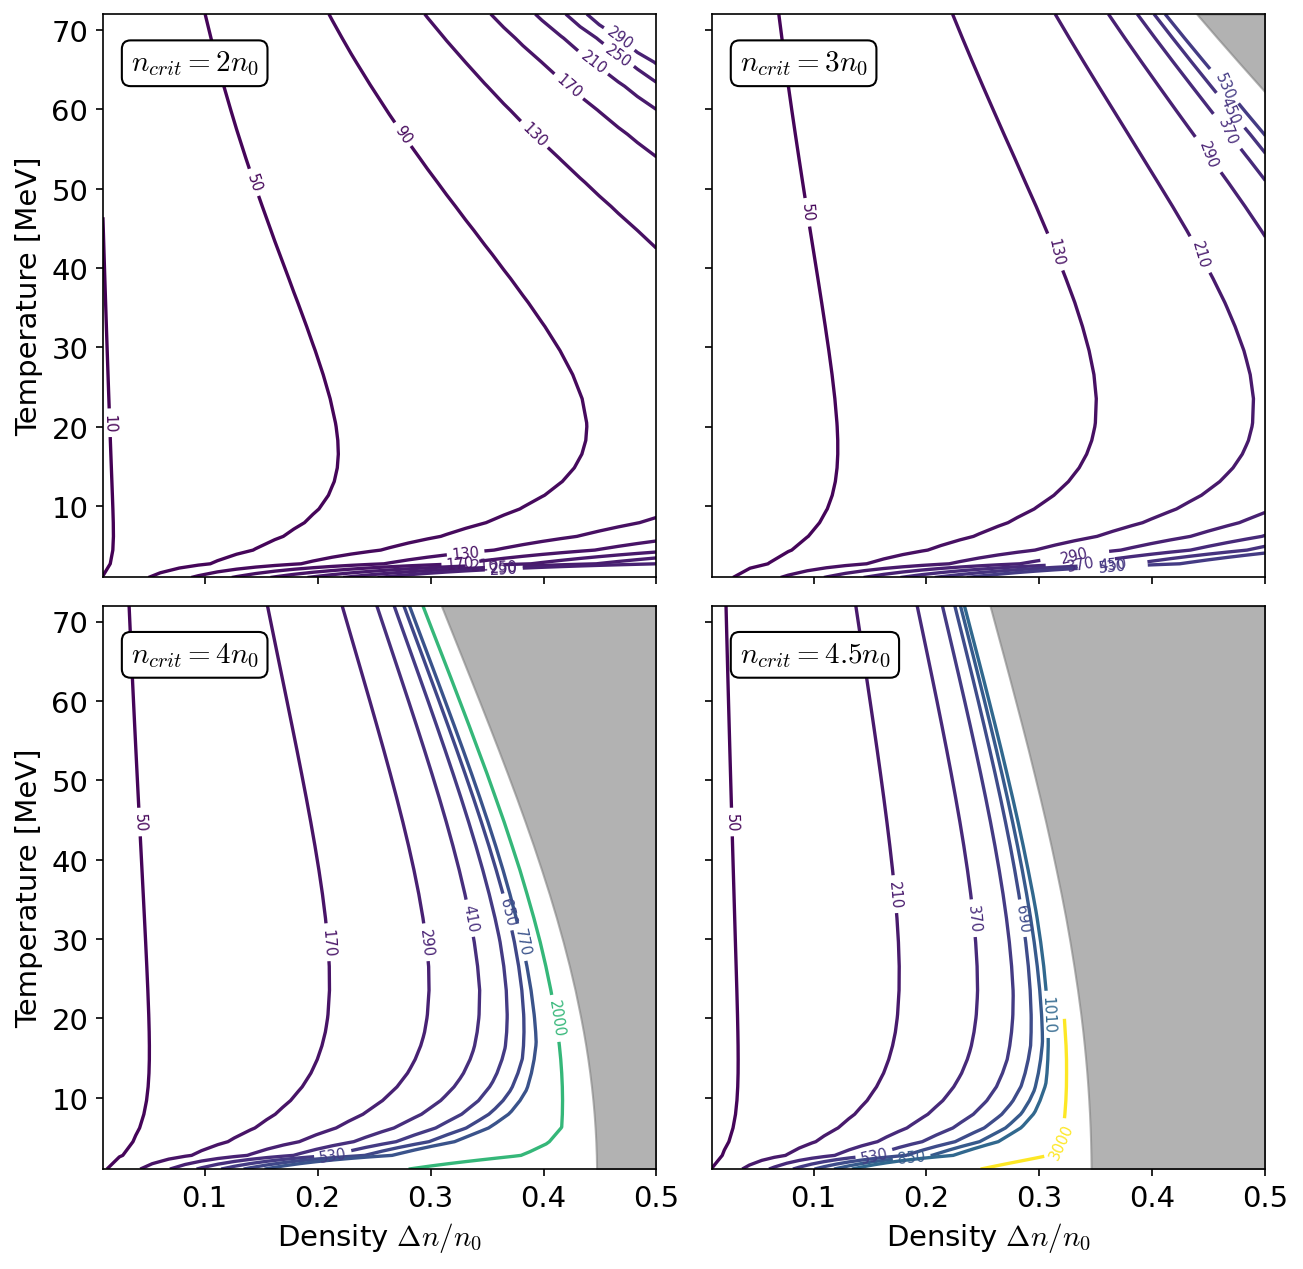

In [110]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM
import matplotlib.colors as mcolors

# Define n0 (adjust as needed)
n0 = 0.16 * const.MeV_fm**3

nc2, nc3, nc4, nc5 = 2*n0, 3*n0, 4*n0, 4.5*n0
N = 30
#level_basic = np.array([50, 80, 110, 140, 170, 200, 260, 350, 440, 530])
path = "/Users/janshao/NSM_related/v_0.002n0/"
path_safe = "/Users/janshao/NSM_related/v_0.015n0_safe/"

al = 0.6

# shaded region
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3.0.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind='linear', fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load("Shade_n_crit=4.0.npy")
Cut4 = interp1d(T_cut4, Deln_cut4, kind='linear', fill_value="extrapolate")

Deln_cut4_5, T_cut4_5 = np.load("Shade_n_crit=4.5.npy")
Cut4_5 = interp1d(T_cut4_5, Deln_cut4_5, kind='linear', fill_value="extrapolate")

# ------------------------------------------------------------------------------------
# --- Shared rainbow mapping so the same numeric level gets the same color everywhere
# ------------------------------------------------------------------------------------
# Levels per subplot
levels_11 = np.concatenate([[10+40*i for i in range(8)]]) #30
levels_12 = np.concatenate([[50+80*i for i in range(7)]]) #60
levels_21 = np.concatenate([[50+120*i for i in range(7)], [2000]]) #90
levels_22 = np.concatenate([[50+160*i for i in range(7)], [3000]]) #120

# Global set of all levels
ALL_LEVELS = np.unique(np.concatenate([levels_11, levels_12, levels_21, levels_22]))

# Rainbow colormap + global normalization across ALL_LEVELS
cmap = plt.get_cmap('viridis')  # use 'turbo' if you prefer a more perceptual rainbow
norm = mcolors.Normalize(vmin=ALL_LEVELS.min(), vmax=ALL_LEVELS.max())

# Fixed color per level via rainbow
LEVEL_COLOR = {lev: cmap(norm(lev)) for lev in ALL_LEVELS}

def contour_with_fixed_colors(ax, X, Y, Z, levels, **kwargs):
    cols = [LEVEL_COLOR[lev] for lev in levels]
    cs = ax.contour(X, Y, Z, levels=levels, colors=cols, **kwargs)
    ax.clabel(cs, inline=True, fontsize=7, fmt="%d")
    return cs

# create plots
fig, axs = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)

# Common T grid
TT = np.hstack([np.linspace(1, 20, int(N*2/5)), np.linspace(20.5, 72, int(N*3/5))])

# ------------------ subplot (0,0): n_crit = 2 n0 ------------------
D2 = np.linspace(0.01*n0, 0.5*n0, N)
V2 = np.load(path+"v_n_crit=2.0.npy")
X20, Y20 = np.meshgrid(D2/n0, TT)
contour_with_fixed_colors(axs[0,0], X20, Y20, V2, levels_11, linewidths=1.6)
axs[0,0].annotate(r"$n_{crit} = 2 n_0$", xy=(0.05, 0.9), xycoords='axes fraction',
                  fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ subplot (0,1): n_crit = 3 n0 ------------------
V3  = np.load(path_safe+"v_n_crit=3.0.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut3(TT)
axs[0,1].fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(axs[0,1], D_grid/n0, T_grid, V3, levels_12, linewidths=1.6, zorder=1)
axs[0,1].set_xlim(0.01, 0.5)
axs[0,1].set_ylim(1, 72)
axs[0,1].annotate(r"$n_{crit} = 3 n_0$", xy=(0.05, 0.9), xycoords='axes fraction',
                  fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ subplot (1,0): n_crit = 4 n0 ------------------
V4  = np.load(path+"v_n_crit=4.0.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut4(TT)
axs[1,0].fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(axs[1,0], D_grid/n0, T_grid, V4, levels_21, linewidths=1.6, zorder=1)
axs[1,0].set_xlim(0.01, 0.5)
axs[1,0].set_ylim(1, 72)
axs[1,0].annotate(r"$n_{crit} = 4 n_0$", xy=(0.05, 0.9), xycoords='axes fraction',
                  fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ subplot (1,1): n_crit = 4.5 n0 ------------------
V4_5  = np.load(path+"v_n_crit=4.5.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4_5(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut4_5(TT)
axs[1,1].fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(axs[1,1], D_grid/n0, T_grid, V4_5, levels_22, linewidths=1.6, zorder=1)
axs[1,1].set_xlim(0.01, 0.5)
axs[1,1].set_ylim(1, 72)
axs[1,1].annotate(r"$n_{crit} = 4.5 n_0$", xy=(0.05, 0.9), xycoords='axes fraction',
                  fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# axes labels
axs[1, 0].set_xlabel(r"Density $\Delta n / n_0$", fontsize=14)
axs[1, 1].set_xlabel(r"Density $\Delta n / n_0$", fontsize=14)
axs[0, 0].set_ylabel("Temperature [MeV]", fontsize=14)
axs[1, 0].set_ylabel("Temperature [MeV]", fontsize=14)

#plt.savefig("2by2_Grid.pdf")
plt.show()

In [42]:
start = time.time()
ve, _ = vNtoQ_nc(
    T = 0.1, 
    n_crit = 3*n0, 
    Deln = 0.5*n0,
    m_s = 0, 
    param=para.paraQMCRMF3, 
    NM_type = 'PNM',
)
end = time.time()

ve, end - start

(np.float64(12004.16837465043), 11.146713018417358)

* based on the new understanding do $z(t)$ plot again with $z_0 = 1$km
* $T = 0.1, 1, 10, 50$ MeV
* log scale of $z(t)$, set ylim to be 1km to 1m
* three rows of plots, linear-linear, linear-log, log-log